# 03 · RQ3: Do agent-assisted commits break the rules?

Two parts. First, the status of each dependency rule from the day it was written to the snapshot. Second, a comparison of **exposed commits** (non-merge commits after a rule was written that change a file the rule covers) between **agent-assisted** and **other** commits.

Uses: `data/processed/dependency_rules.csv`, `rule_candidate_sentences.csv`, `rule_attribution.csv`, `exposed_commits.csv`, and the manual-check sheets `manual_review/R3`–`R7`.

In [1]:
import os, sys; sys.path.insert(0, '../src' if os.path.basename(os.getcwd()) == 'notebooks' else 'src')
from analysis_helpers import *   # moves to the package root and loads helpers
rules, sent = load('dependency_rules'), load('rule_candidate_sentences')
commits = load('exposed_commits')
N = {}

## 1 · From sentences to checkable rules

In [2]:
dep = sent.category.isin(['internal_boundary', 'external_boundary'])
N['funnel'] = dict(sentences=len(sent), projects=sent.repo.nunique(), dependency_rules=int(dep.sum()), checkable_sentences=int((dep & sent.checkable).sum()),
                   checkable_rules=len(rules), rule_projects=rules.repo.nunique())
print(N['funnel'])
print(rules.rule_type.value_counts().to_string()); print(rules.polarity.value_counts().to_string())
rules.drop_duplicates('repo').language.value_counts().rename('projects with rules').to_frame().T

{'sentences': 1645, 'projects': 875, 'dependency_rules': 357, 'checkable_sentences': 176, 'checkable_rules': 184, 'rule_projects': 115}
rule_type
internal            126
external_library     58
polarity
forbid    176
only        8


language,TypeScript,Python,Go,Java,Rust,PHP,C#,JavaScript,C,C++
projects with rules,46,23,12,9,7,5,4,4,3,2


## 2 · Rule status, and manual check R3 of rules broken when written

In [3]:
R3 = review_labels('R3_rules_broken_when_written')
rules['review'] = rules.rule_id.map(R3.set_index('rule_id').label)
N['status'] = rules.status.value_counts().to_dict()
N['still_broken_at_snapshot'] = int(((rules.status == 'broken_when_written') & (rules.breaking_imports_at_snapshot > 0)).sum())
N['r3_labels'] = rules.review.value_counts().to_dict()
conf = rules.review == 'CONFIRMED_BROKEN'
N['confirmed_broken'] = int(conf.sum()); N['projects_with_confirmed'] = rules.assign(c=conf).groupby('repo').c.any().mean()
N['confirmed_still_broken'] = int((conf & (rules.breaking_imports_at_snapshot > 0)).sum())
print(N['status']); print(N['r3_labels'])
print(f"confirmed broken when written: {N['confirmed_broken']} of {len(rules)} ({pct(N['confirmed_broken']/len(rules))}), "
      f"in {pct(N['projects_with_confirmed'], 0)} of projects with rules")
rules.assign(confirmed=conf).groupby('rule_type').agg(rules=('rule_id', 'size'), broken_when_written=('status', lambda s: (s == 'broken_when_written').sum()), confirmed=('confirmed', 'sum'))

R3_rules_broken_when_written: 51 items
{'held': 129, 'broken_when_written': 51, 'broken_later': 4}
{'CONFIRMED_BROKEN': 33, 'FALSE_MAPPING': 15, 'FALSE_RESOLUTION': 2, 'UNCLEAR': 1}
confirmed broken when written: 33 of 184 (17.9%), in 21% of projects with rules


,rules,broken_when_written,confirmed
rule_type,,,
external_library,58,24,14
internal,126,27,19


**Manual check R4**: in rules the checker found intact, did it miss breaks? This gives a lower-bound warning for the numbers above.

In [4]:
R4 = review_labels('R4_rules_that_held')
N['r4'] = R4.label.value_counts().to_dict(); N['r4']

R4_rules_that_held: 40 items


{'HOLDS': 35, 'MISSED_VIOLATION': 5}

**Who wrote the broken rules, and how old is the code that breaks them?** (`rule_attribution.csv`, confirmed rules only). *lines older than window* = rule-breaking imports already present before the project's first context file.

In [5]:
A = load('rule_attribution'); A = A[A.rule_id.isin(rules[conf].rule_id)]
N['attribution'] = dict(rules=len(A), rule_written_by_agent=int((A.rule_written_by == 'agent').sum()),
                        all_breaking_code_older=int((A.lines_older_than_window == A.checked).sum()),
                        some_breaking_code_by_agent=int((A.lines_added_by_agent_assisted > 0).sum()))
N['attribution']

{'rules': 33,
 'rule_written_by_agent': 9,
 'all_breaking_code_older': 26,
 'some_breaking_code_by_agent': 4}

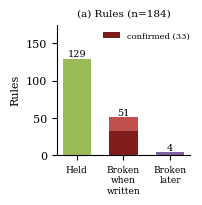

In [6]:
fig, a1 = plt.subplots(figsize=(FIG_W / 2, 1.7))
s = N['status']; vals = [s.get('held', 0), s.get('broken_when_written', 0), s.get('broken_later', 0)]
a1.bar(range(3), vals, color=['#9bbb59', '#c0504d', '#8064a2'], width=.6)
a1.bar([1], [N['confirmed_broken']], color='#7f1d1d', width=.6, label=f"confirmed ({N['confirmed_broken']})")
for i, v in enumerate(vals): a1.text(i, v + 3, str(v), ha='center', fontsize=7)
a1.set_xticks(range(3)); a1.set_xticklabels(['Held', 'Broken\nwhen\nwritten', 'Broken\nlater'], fontsize=6.5); a1.set_ylabel('Rules'); a1.set_ylim(0, 175)
a1.set_title(f'(a) Rules (n={len(rules)})', fontsize=7.5); a1.legend(fontsize=6, frameon=False, loc='upper right', bbox_to_anchor=(1.05, 1.0))
plt.savefig(f'{FIGS}/rq3a.pdf', bbox_inches='tight'); plt.show()

## 3 · Commit groups and manual check R7 of agent labels

In [7]:
N['commits'] = commits.group.value_counts().to_dict(); N['commit_projects'] = commits.repo.nunique()
N['agent_projects'] = commits[commits.group == 'agent_assisted'].repo.nunique()
ag = commits[commits.group == 'agent_assisted']
N['traces'] = {'message (S1/S2)': int(ag.trace_message.sum()),
               'account only (S3)': int((ag.trace_agent_account & ~ag.trace_message).sum()),
               'pull request only (S4-S6)': int((ag.trace_pull_request & ~ag.trace_message & ~ag.trace_agent_account).sum())}
print(N['commits'], N['commit_projects'], 'projects;', N['agent_projects'], 'with agent-assisted commits'); N['traces']

{'other': 5752, 'agent_assisted': 1728} 96 projects; 56 with agent-assisted commits


{'message (S1/S2)': 1332,
 'account only (S3)': 65,
 'pull request only (S4-S6)': 331}

In [8]:
R7 = review_labels('R7_agent_commit_labels')
pd.crosstab(R7.detector_group, R7.label)

R7_agent_commit_labels: 150 items


label,AGENT,NO_EVIDENCE
detector_group,,
agent_assisted,96,1
other,3,50


## 4 · New rule breaks: manual checks R5 (flagged commits) and R6 (unflagged commits)

A flagged commit counts as **confirmed** if at least one of its flagged commit-rule pairs is labelled `CONFIRMED`.

In [9]:
R5 = review_labels('R5_flagged_commits')
confirmed_shas = set(R5[R5.label == 'CONFIRMED'].commit)
commits['confirmed'] = commits.sha.isin(confirmed_shas) & commits.flagged_break
R6 = review_labels('R6_unflagged_commits'); N['r6'] = R6.label.value_counts().to_dict()
t = commits.groupby('group').agg(commits=('sha', 'size'), flagged=('flagged_break', 'sum'), confirmed=('confirmed', 'sum'), repairs=('repair', 'sum'))
t['flagged %'] = t.flagged / t.commits * 100; t['confirmed %'] = t.confirmed / t.commits * 100
N['breaks'] = t.to_dict(); print('R6:', N['r6'])
t.style.format({'flagged %': '{:.2f}', 'confirmed %': '{:.2f}'})

R5_flagged_commits: 35 items
R6_unflagged_commits: 100 items
R6: {'NO_BREAK': 100}


,commits,flagged,confirmed,repairs,flagged %,confirmed %
group,,,,,,
agent_assisted,1728,7,5,2,0.41,0.29
other,5752,23,9,27,0.40,0.16


## 5 · The one test: Mantel-Haenszel odds ratio, within projects

New breaks are rare, and commits in the same project are alike. So we build one 2×2 table per project (agent-assisted vs. other × confirmed break or not) for projects that have both groups, and combine them. An odds ratio of 1 means no difference.

In [10]:
from statsmodels.stats.contingency_tables import StratifiedTable
tables = []
for repo, x in commits.groupby('repo'):
    a, o = x[x.group == 'agent_assisted'], x[x.group == 'other']
    if len(a) and len(o):
        tables.append(np.array([[a.confirmed.sum(), len(a) - a.confirmed.sum()], [o.confirmed.sum(), len(o) - o.confirmed.sum()]]))
mh = StratifiedTable(tables); lo, hi = mh.oddsratio_pooled_confint()
N['mantel_haenszel'] = dict(odds_ratio=mh.oddsratio_pooled, ci_low=lo, ci_high=hi, p=mh.test_null_odds(correction=True).pvalue,
                            projects=len(tables), projects_with_any_break=int(sum(t_[:, 0].sum() > 0 for t_ in tables)))
N['mantel_haenszel']

{'odds_ratio': np.float64(2.6383404243702144),
 'ci_low': np.float64(0.6855266139655676),
 'ci_high': np.float64(10.154004312975703),
 'p': np.float64(0.20894000283513425),
 'projects': 51,
 'projects_with_any_break': 8}

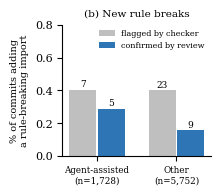

In [11]:
fig, a2 = plt.subplots(figsize=(FIG_W / 1.8, 1.7)); x = np.arange(2)
for j, (col, colr, lab) in enumerate([('flagged', '#bfbfbf', 'flagged by checker'), ('confirmed', '#2e75b6', 'confirmed by review')]):
    v = [t.loc[w, f'{col} %'] for w in ['agent_assisted', 'other']]
    a2.bar(x + (j - .5) * .36, v, width=.34, color=colr, label=lab)
    for i, w in enumerate(['agent_assisted', 'other']): a2.text(x[i] + (j - .5) * .36, v[i] + .015, str(int(t.loc[w, col])), ha='center', fontsize=6.5)
a2.set_xticks(x); a2.set_xticklabels([f"Agent-assisted\n(n={t.loc['agent_assisted','commits']:,})", f"Other\n(n={t.loc['other','commits']:,})"], fontsize=6.3)
a2.set_ylim(0, .8); a2.set_ylabel('% of commits adding\na rule-breaking import', fontsize=7); a2.set_title('(b) New rule breaks', fontsize=7.5)
a2.legend(fontsize=5.8, frameon=False, loc='upper center', bbox_to_anchor=(0.6, 1.02))
plt.savefig(f'{FIGS}/rq3b.pdf', bbox_inches='tight'); plt.show()

In [12]:
save_numbers('rq3_numbers', N); print('saved results/rq3_numbers.json')

saved results/rq3_numbers.json
